# Baseline Regression Models

**Goal:** Predict photometric redshift (`specz`) from SDSS DR17 photometric features.  
We test a wide range of regression models and compare them by **Test RMSE** and **R² score**.

| Feature group | Columns |
|---|---|
| Magnitudes | `modelMag_u`, `modelMag_g`, `modelMag_r`, `modelMag_i`, `modelMag_z` |
| Colors | `color_u_g`, `color_g_r`, `color_r_i`, `color_i_z` |

**Target:** `specz` (spectroscopic redshift)

In [6]:
# ── 0. Imports ────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    BayesianRidge, SGDRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    ExtraTreesRegressor, AdaBoostRegressor, BaggingRegressor
)
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

print('All imports successful.')

All imports successful.


In [7]:
# ── 1. Load Data ──────────────────────────────────────────────────────────────
DATA_PATH = '../data/processed/sdss_dr17_galaxies_processed.csv'

df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (49963, 11)


,objID,modelMag_u,modelMag_g,modelMag_r,modelMag_i,modelMag_z,specz,color_u_g,color_g_r,color_r_i,color_i_z
0,1237648702967119953,19.71478,18.16947,17.33998,16.92702,16.58958,0.070971,1.54531,0.82949,0.41296,0.33744
1,1237648702967120032,22.23305,19.84204,18.21035,17.57529,17.23127,0.326429,2.39101,1.63169,0.63506,0.34402
2,1237648702967185504,19.53371,18.75589,18.26050,17.93995,17.85650,0.157200,0.77782,0.49539,0.32055,0.08345
3,1237648702967185512,20.35386,18.23603,17.19775,16.73129,16.38129,0.118066,2.11783,1.03828,0.46646,0.35000
4,1237648702967185534,20.63783,18.84690,17.83532,17.42388,17.07543,0.117932,1.79093,1.01158,0.41144,0.34845


In [8]:
# ── 2. Feature / Target Split ─────────────────────────────────────────────────
FEATURE_COLS = [
    'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z',
    'color_u_g', 'color_g_r', 'color_r_i', 'color_i_z'
]
TARGET_COL = 'specz'

X = df[FEATURE_COLS].values
y = df[TARGET_COL].values

print(f'Features : {X.shape}  |  Target : {y.shape}')
print(f'Redshift range : [{y.min():.4f}, {y.max():.4f}]  |  mean = {y.mean():.4f}')

Features : (49963, 9)  |  Target : (49963,)
Redshift range : [0.0100, 0.4999]  |  mean = 0.1373


In [9]:
# ── 3. Train / Test Split  (test_size = 0.10) ─────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42
)

print(f'Train samples : {X_train.shape[0]:,}')
print(f'Test  samples : {X_test.shape[0]:,}')

Train samples : 44,966
Test  samples : 4,997


In [10]:
# ── 4. Define Models ──────────────────────────────────────────────────────────
# Each model is wrapped in a Pipeline with StandardScaler so all models
# receive normalised input regardless of scale sensitivity.

def make_pipeline(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

MODELS = {
    'Linear Regression'       : make_pipeline(LinearRegression()),
    'Ridge'                   : make_pipeline(Ridge(alpha=1.0)),
    'Lasso'                   : make_pipeline(Lasso(alpha=0.001, max_iter=5000)),
    'ElasticNet'              : make_pipeline(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=5000)),
    'Bayesian Ridge'          : make_pipeline(BayesianRidge()),
    'SGD Regressor'           : make_pipeline(SGDRegressor(max_iter=1000, tol=1e-4, random_state=42)),
    'K-Nearest Neighbors'     : make_pipeline(KNeighborsRegressor(n_neighbors=10, n_jobs=-1)),
    'Decision Tree'           : make_pipeline(DecisionTreeRegressor(max_depth=10, random_state=42)),
    'Random Forest'           : make_pipeline(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
    'Extra Trees'             : make_pipeline(ExtraTreesRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
    'Gradient Boosting'       : make_pipeline(GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)),
    'AdaBoost'                : make_pipeline(AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42)),
    'Bagging Regressor'       : make_pipeline(BaggingRegressor(n_estimators=50, n_jobs=-1, random_state=42)),
    'Support Vector Regressor': make_pipeline(SVR(kernel='rbf', C=10, epsilon=0.01)),
    'MLP Neural Network'      : make_pipeline(MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=500,
                                                            learning_rate_init=0.001, random_state=42)),
}

print(f'Total models to evaluate: {len(MODELS)}')

Total models to evaluate: 15


In [11]:
# ── 5. Train & Evaluate All Models ────────────────────────────────────────────
results = []

for name, pipeline in MODELS.items():
    print(f'  Training  →  {name} ...', end='', flush=True)
    t0 = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = pipeline.predict(X_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    r2     = r2_score(y_test, y_pred)

    results.append({
        'Model'       : name,
        'Test RMSE'   : round(rmse, 6),
        'R² Score'    : round(r2, 6),
        'Train Time(s)': round(train_time, 2),
    })
    print(f'  RMSE={rmse:.5f}  R²={r2:.5f}  ({train_time:.1f}s)')

print('\n✅ Done!')

  Training  →  Linear Regression ...  RMSE=0.04633  R²=0.78333  (0.0s)
  Training  →  Ridge ...  RMSE=0.04633  R²=0.78333  (0.0s)
  Training  →  Lasso ...  RMSE=0.04659  R²=0.78091  (0.2s)
  Training  →  ElasticNet ...  RMSE=0.04645  R²=0.78218  (0.3s)
  Training  →  Bayesian Ridge ...  RMSE=0.04633  R²=0.78333  (0.1s)
  Training  →  SGD Regressor ...  RMSE=0.04768  R²=0.77055  (0.1s)
  Training  →  K-Nearest Neighbors ...  RMSE=0.02591  R²=0.93223  (0.1s)
  Training  →  Decision Tree ...  RMSE=0.02920  R²=0.91394  (0.7s)
  Training  →  Random Forest ...  RMSE=0.02487  R²=0.93759  (7.0s)
  Training  →  Extra Trees ...  RMSE=0.02468  R²=0.93853  (2.7s)
  Training  →  Gradient Boosting ...  RMSE=0.02462  R²=0.93883  (85.2s)
  Training  →  AdaBoost ...  RMSE=0.03811  R²=0.85338  (22.1s)
  Training  →  Bagging Regressor ...  RMSE=0.02501  R²=0.93687  (14.3s)
  Training  →  Support Vector Regressor ...  RMSE=0.02698  R²=0.92653  (646.6s)
  Training  →  MLP Neural Network ...  RMSE=0.02676  

In [12]:
# ── 6. Results Table ──────────────────────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('Test RMSE').reset_index(drop=True)
results_df.index += 1   # rank starts at 1

# highlight best row
def highlight_best(s):
    is_best = s == s.min()
    return ['background-color: #d4edda; font-weight: bold' if v else '' for v in is_best]

print('=== Regression Model Comparison (sorted by Test RMSE) ===')
results_df.style \
    .apply(highlight_best, subset=['Test RMSE']) \
    .format({'Test RMSE': '{:.6f}', 'R² Score': '{:.6f}', 'Train Time(s)': '{:.2f}'})

=== Regression Model Comparison (sorted by Test RMSE) ===


,Model,Test RMSE,R² Score,Train Time(s)
1,Gradient Boosting,0.024618,0.938826,85.16
2,Extra Trees,0.024677,0.938533,2.73
3,Random Forest,0.024866,0.937590,7.03
4,Bagging Regressor,0.025010,0.936866,14.34
5,K-Nearest Neighbors,0.025911,0.932233,0.15
6,MLP Neural Network,0.026758,0.927729,9.28
7,Support Vector Regressor,0.026979,0.926532,646.59
8,Decision Tree,0.029200,0.913939,0.74
9,AdaBoost,0.038113,0.853381,22.08
10,Linear Regression,0.046331,0.783328,0.05


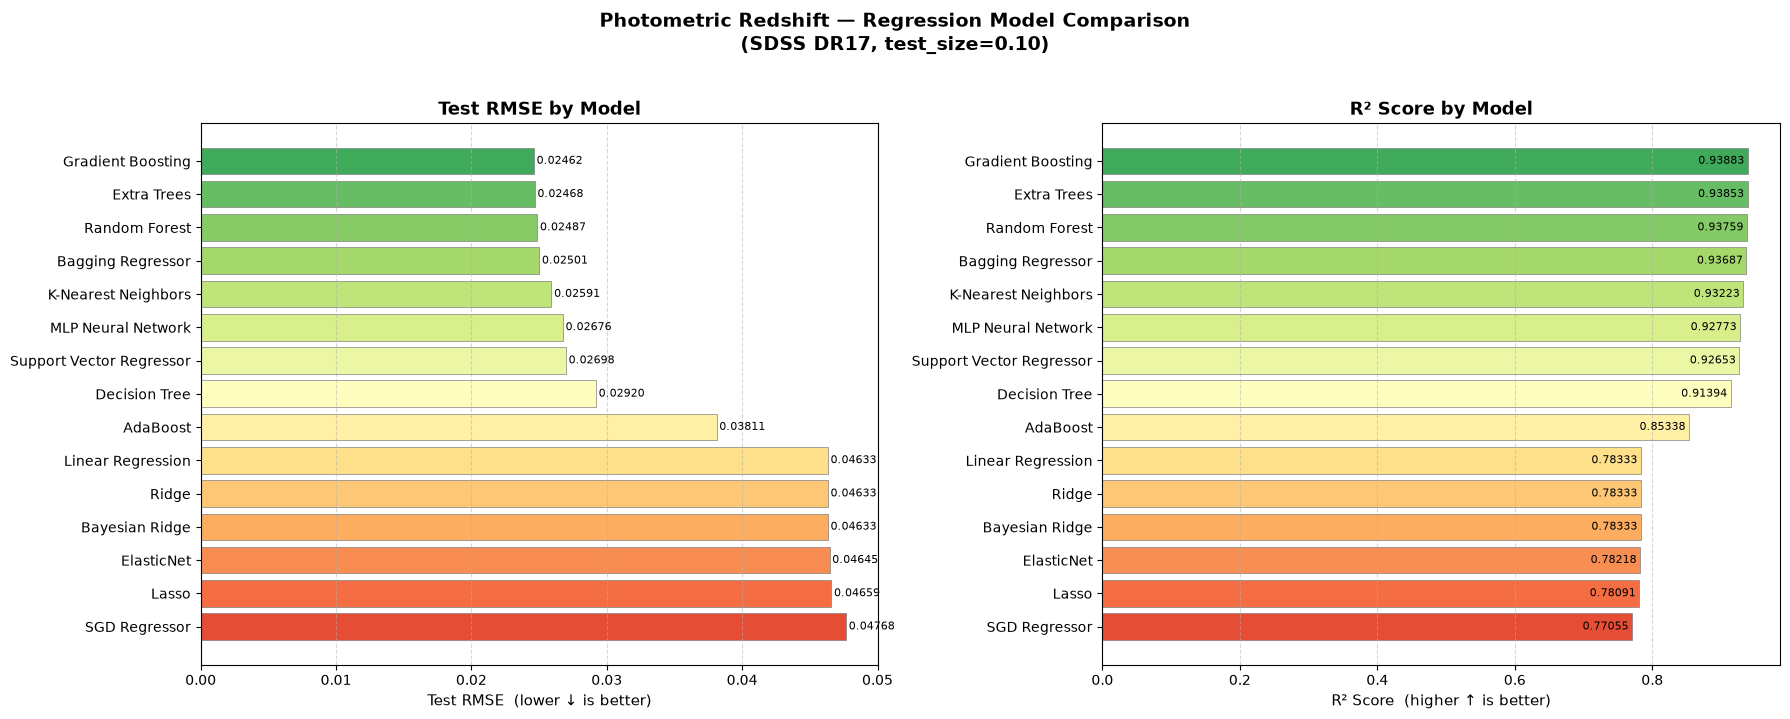

Figure saved → results/figures/model_comparison.png


In [13]:
# ── 7. Bar Charts ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colors = cm.RdYlGn_r(np.linspace(0.15, 0.85, len(results_df)))

# — RMSE (lower is better)
ax = axes[0]
bars = ax.barh(results_df['Model'][::-1], results_df['Test RMSE'][::-1], color=colors[::-1], edgecolor='grey', linewidth=0.5)
for bar, val in zip(bars, results_df['Test RMSE'][::-1]):
    ax.text(bar.get_width() + 0.0002, bar.get_y() + bar.get_height()/2,
            f'{val:.5f}', va='center', fontsize=8)
ax.set_xlabel('Test RMSE  (lower ↓ is better)', fontsize=11)
ax.set_title('Test RMSE by Model', fontsize=13, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)

# — R² (higher is better)
colors2 = cm.RdYlGn(np.linspace(0.15, 0.85, len(results_df)))
sorted_r2 = results_df.sort_values('R² Score', ascending=True)
ax2 = axes[1]
bars2 = ax2.barh(sorted_r2['Model'], sorted_r2['R² Score'], color=colors2, edgecolor='grey', linewidth=0.5)
for bar, val in zip(bars2, sorted_r2['R² Score']):
    ax2.text(bar.get_width() - 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.5f}', va='center', ha='right', fontsize=8, color='black')
ax2.set_xlabel('R² Score  (higher ↑ is better)', fontsize=11)
ax2.set_title('R² Score by Model', fontsize=13, fontweight='bold')
ax2.grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Photometric Redshift — Regression Model Comparison\n(SDSS DR17, test_size=0.10)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved → results/figures/model_comparison.png')

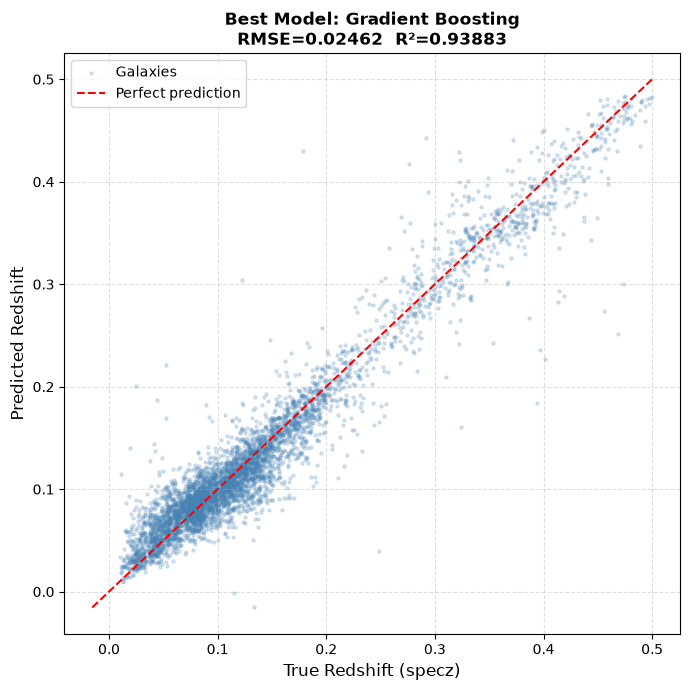

Best model: Gradient Boosting


In [14]:
# ── 8. Predicted vs Actual — Best Model ───────────────────────────────────────
best_name = results_df.iloc[0]['Model']
best_pipeline = MODELS[best_name]
y_best_pred = best_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_best_pred, alpha=0.2, s=5, color='steelblue', label='Galaxies')
lims = [min(y_test.min(), y_best_pred.min()), max(y_test.max(), y_best_pred.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect prediction')
ax.set_xlabel('True Redshift (specz)', fontsize=12)
ax.set_ylabel('Predicted Redshift', fontsize=12)
ax.set_title(f'Best Model: {best_name}\nRMSE={results_df.iloc[0]["Test RMSE"]:.5f}  R²={results_df.iloc[0]["R² Score"]:.5f}',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('../results/figures/best_model_pred_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Best model: {best_name}')

In [15]:
# ── 9. Save Results CSV ───────────────────────────────────────────────────────
out_path = '../results/metrics/model_comparison.csv'
results_df.to_csv(out_path)
print(f'Results saved → {out_path}')

# Final summary print
print('\n' + '='*60)
print('  FINAL LEADERBOARD')
print('='*60)
print(results_df[['Model', 'Test RMSE', 'R² Score']].to_string(index=True))
print('='*60)
print(f'\n🏆  Best model → {best_name}  (RMSE={results_df.iloc[0]["Test RMSE"]:.5f})')

Results saved → ../results/metrics/model_comparison.csv

  FINAL LEADERBOARD
                       Model  Test RMSE  R² Score
1          Gradient Boosting   0.024618  0.938826
2                Extra Trees   0.024677  0.938533
3              Random Forest   0.024866  0.937590
4          Bagging Regressor   0.025010  0.936866
5        K-Nearest Neighbors   0.025911  0.932233
6         MLP Neural Network   0.026758  0.927729
7   Support Vector Regressor   0.026979  0.926532
8              Decision Tree   0.029200  0.913939
9                   AdaBoost   0.038113  0.853381
10         Linear Regression   0.046331  0.783328
11                     Ridge   0.046331  0.783328
12            Bayesian Ridge   0.046332  0.783326
13                ElasticNet   0.046454  0.782180
14                     Lasso   0.046589  0.780913
15             SGD Regressor   0.047677  0.770554

🏆  Best model → Gradient Boosting  (RMSE=0.02462)
